# Step 1 — Understand the vibration data

The task is to compress wind-turbine vibration with a learned model. This notebook does not train one. It checks what a row of the file actually contains, and which traits of that signal a compressor can use.

**Source.** Sergio Martin del Campo Barraza, Fredrik Sandin, and Daniel Strömbergsson, *Dataset concerning the vibration signals from wind turbines in northern Sweden*, Luleå University of Technology (2018), republished on SND in 2024. DOI [10.5878/bcmv-wq08](https://doi.org/10.5878/bcmv-wq08). Catalogue entry [2024-248](https://researchdata.se/catalogue/dataset/2024-248).

The release is six CSV files, `DATASET02.csv` through `DATASET07.csv`, one file per turbine. This notebook uses only `DATASET02.csv`.

**What one row is.** There is no header. The dataset description says:

- column 0 is time, in years since the recording started
- column 1 is rotational speed, in RPM
- the remaining columns are one vibration segment, in g, from a single axial accelerometer on the output-shaft bearing housing

The same description says the sampling rate is 12.8 kHz and each segment lasts 1.28 s, which is 16,384 samples. The file does not store a clock on each sample, so this notebook checks the sample count and then uses 12.8 kHz because 16,384 / 12,800 = 1.28 exactly.

**Why this subset.** `DATASET02.csv` is about 850 MB, and the other five files are the same kind of recording on the same kind of turbine, with the same sensor placement. Reading all of them would not reveal a new signal structure.

What does change the waveform is the operating speed. Shaft tones sit at multiples of RPM / 60, so a segment at 700 RPM is not the same shape as a segment at 900 RPM. The rows are stored in time order, and the speed is not constant, so the start of the file is only one part of the campaign.

The notebook therefore keeps every **complete** row inside five 2 MB windows of `DATASET02.csv`: the start, one quarter of the way through, halfway, three quarters, and the end. A window is a byte range, so the line cut by each edge is dropped. That is a few dozen segments, spread across the years of this turbine and across the speeds that actually occur in those windows. It is enough to see the waveform, the spectrum, the amplitude, and how predictable the next sample is. It is not a claim about the other five turbines, or about speeds that never appear in these windows.


In [1]:
import numpy as np

from signals import FS, energy_bins, load_subset, main_peak, row_stats, spectrum

years, rpm, samples, text_bytes, file_size = load_subset()
n_seg, n_samples = samples.shape
print(f"DATASET02.csv is {file_size:,} bytes")
print(f"subset: {n_seg} segments x {n_samples} samples")
print(f"years {years.min():.3f} to {years.max():.3f}")
print(f"speed {rpm.min():.1f} to {rpm.max():.1f} RPM")


loaded data/dataset02.npz (27 segments)
DATASET02.csv is 893,424,837 bytes
subset: 27 segments x 16384 samples
years 0.000 to 3.844
speed 705.4 to 1160.5 RPM


## What was kept

Each kept row is one 1.28 s recording, plus the two numbers in front of it. The table is sorted by speed so the operating range is easy to scan.

- **rms_g** — typical amplitude of that segment
- **peak_g** — largest absolute sample
- **kurt** — fourth standardized moment. A Gaussian is 3. Larger means sharper occasional peaks
- **lag1** — correlation between a sample and the next one
- **dstd** — standard deviation of the first difference, divided by the standard deviation of the raw segment. Smaller means a delta code has less to send


In [2]:
stats = [row_stats(x) for x in samples]
order = np.argsort(rpm)

header = f"{'i':>3} {'years':>8} {'rpm':>8} {'rms_g':>8} {'peak_g':>8} {'kurt':>7} {'lag1':>7} {'dstd':>7}"
print(header)
print("-" * len(header))
for i in order:
    row = stats[i]
    print(
        f"{i:3d} {years[i]:8.3f} {rpm[i]:8.1f} {row['rms']:8.3f} "
        f"{row['peak']:8.3f} {row['kurt']:7.1f} {row['lag1']:7.3f} {row['dstd']:7.3f}"
    )

print()
print(f"Published rate {FS} Hz x {n_samples} samples = {n_samples / FS:.2f} s per segment.")
print(f"CSV text is {text_bytes.mean() / 1e3:.0f} KB per row on average.")
print(f"The same samples as float32 are {n_samples * 4 / 1e3:.1f} KB, and as float64 {n_samples * 8 / 1e3:.1f} KB.")
err_f32 = np.max(np.abs(samples - samples.astype(np.float32)))
print(f"Largest change if these values are stored as float32: {err_f32:.3e} g.")


  i    years      rpm    rms_g   peak_g    kurt    lag1    dstd
---------------------------------------------------------------
  6    0.709    705.4    0.211    0.806     3.0   0.824   0.594
  1    0.001    709.4    0.203    0.943     3.2   0.749   0.708
  2    0.002    713.1    0.432    1.264     2.2   0.922   0.394
 15    1.667    743.5    0.218    1.055     3.5   0.816   0.606
  0    0.000    750.9    0.322    1.305     2.9   0.721   0.747
 26    3.844    794.0    0.560    1.956     2.7   0.860   0.529
 24    3.841    803.4    0.492    1.855     2.8   0.846   0.555
 20    2.754    818.5    0.606    2.744     2.9   0.837   0.571
 16    2.749    819.8    0.565    2.334     2.9   0.833   0.577
 11    1.662    844.5    0.716    3.038     3.1   0.811   0.614
 18    2.751    861.1    0.865    3.250     2.9   0.829   0.585
  5    0.005    878.0    0.257    1.186     3.3   0.637   0.852
 22    3.837    880.6    0.758    3.157     3.0   0.849   0.550
  9    0.712    883.7    0.672    2.746 

## Waveform

Three segments: the slowest, the one nearest the middle of the speed range, and the fastest. The left column is the whole 1.28 s. Inside one segment the amplitude stays in a steady band, and that band gets taller as the turbine spins faster. The right column is the first 20 ms, short enough to see the oscillation itself.


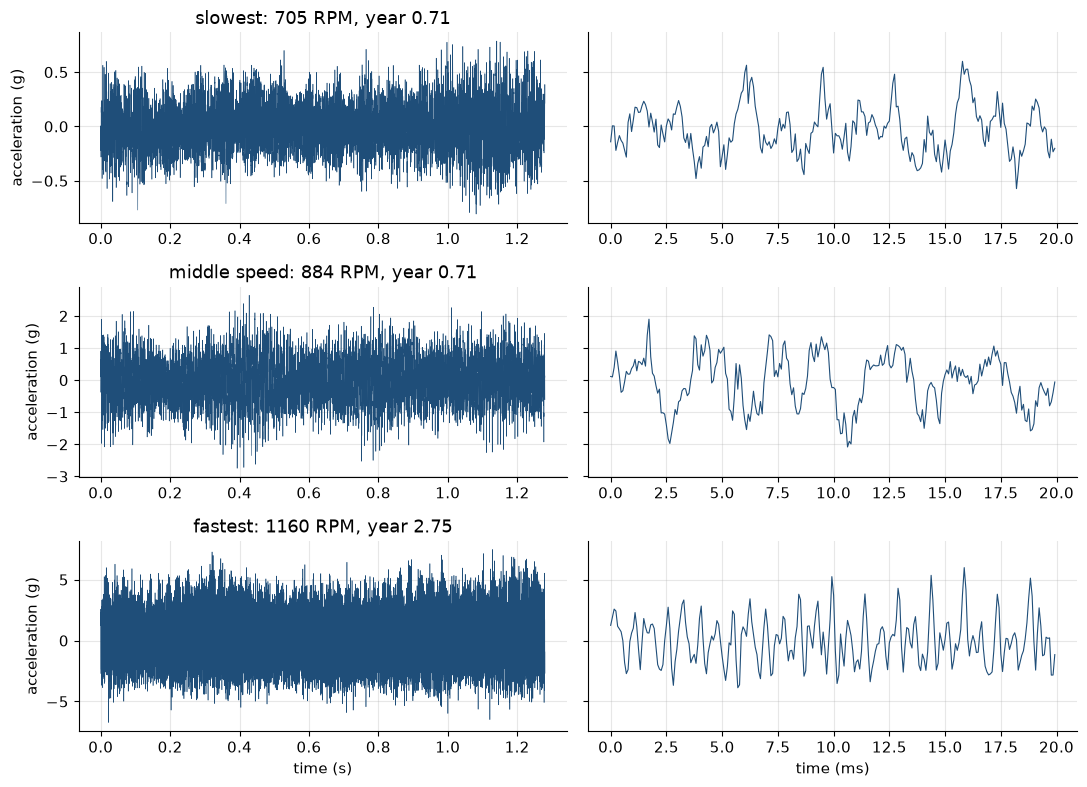

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

mid = order[len(order) // 2]
picked = [order[0], mid, order[-1]]
labels = ["slowest", "middle speed", "fastest"]
zoom_n = int(0.02 * FS)
t_full = np.arange(n_samples) / FS
t_zoom = t_full[:zoom_n]

fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharey="row")
for row, (i, label) in enumerate(zip(picked, labels)):
    axes[row, 0].plot(t_full, samples[i], color="#1f4e79", lw=0.4)
    axes[row, 1].plot(t_zoom * 1e3, samples[i, :zoom_n], color="#1f4e79", lw=0.8)
    axes[row, 0].set_ylabel("acceleration (g)")
    axes[row, 0].set_title(f"{label}: {rpm[i]:.0f} RPM, year {years[i]:.2f}")
axes[2, 0].set_xlabel("time (s)")
axes[2, 1].set_xlabel("time (ms)")
fig.tight_layout()
plt.show()


## Where the energy sits

The shaft rate is RPM / 60. In this subset that is about 12–19 Hz, which is the obvious place to look. It is not where the energy is.

The left column is frequency in hertz, up to 2.5 kHz. The right column is the same spectrum divided by the shaft rate, in shaft orders. A line that is a fixed multiple of the shaft stays put on the right when the turbine speeds up, and it moves on the left. The orange line is the single loudest peak of that segment, ignoring anything below 40 Hz.

These three rows are segments whose loudest line is near order 35, taken at a low, middle, and high speed. That is the common case in this subset. The scatter further down shows the segments that land somewhere else.

The file does not include tooth counts, so order 35 is not given a gear name. For compression, the useful fact is that the loud frequency is the speed times a stable number.


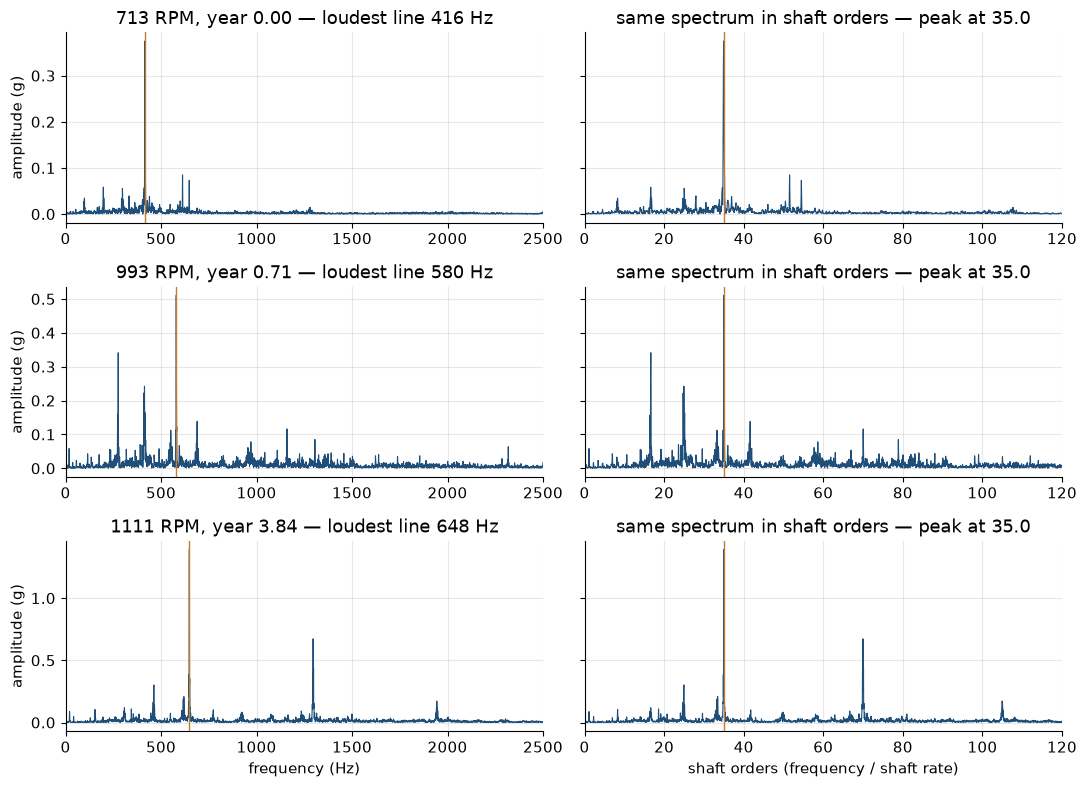

In [4]:
FMAX = 2500
OMAX = 120
# Waveform above is the speed extremes. These three are the common case:
# loudest line near order 35, at a low, middle, and high speed.
orders = np.array([main_peak(samples[i], rpm[i])[1] for i in range(n_seg)])
at_35 = np.flatnonzero(np.abs(orders - 35) < 0.5)
at_35 = at_35[np.argsort(rpm[at_35])]
show = [at_35[0], at_35[len(at_35) // 2], at_35[-1]]

fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharey="row")
for row, i in enumerate(show):
    freq, amp = spectrum(samples[i], FS)
    hz, odr = main_peak(samples[i], rpm[i])
    keep = freq <= FMAX
    axes[row, 0].plot(freq[keep], amp[keep], color="#1f4e79", lw=0.8)
    axes[row, 0].axvline(hz, color="#c47b2b", lw=1.0)
    axes[row, 0].set_xlim(0, FMAX)
    axes[row, 0].set_ylabel("amplitude (g)")
    axes[row, 0].set_title(f"{rpm[i]:.0f} RPM, year {years[i]:.2f} — loudest line {hz:.0f} Hz")

    shaft_orders = freq / (rpm[i] / 60.0)
    keep = shaft_orders <= OMAX
    axes[row, 1].plot(shaft_orders[keep], amp[keep], color="#1f4e79", lw=0.8)
    axes[row, 1].axvline(odr, color="#c47b2b", lw=1.0)
    axes[row, 1].set_xlim(0, OMAX)
    axes[row, 1].set_title(f"same spectrum in shaft orders — peak at {odr:.1f}")

axes[2, 0].set_xlabel("frequency (Hz)")
axes[2, 1].set_xlabel("shaft orders (frequency / shaft rate)")
fig.tight_layout()
plt.show()


## What is worth compressing

Three facts, across every segment in the subset:

- amplitude against speed
- the shaft order of the loudest line (frequency divided by RPM / 60)
- how many frequency bins are needed to hold 90% of the power, out of 8,192

The histogram under that compares the raw samples with the first difference, for the middle-speed segment. If the difference were much narrower, storing “change from the previous sample” would already be a strong compressor.


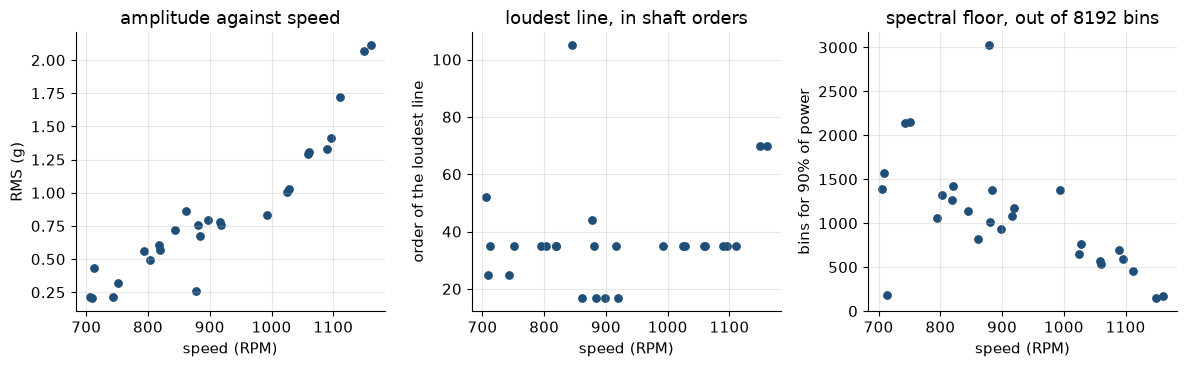

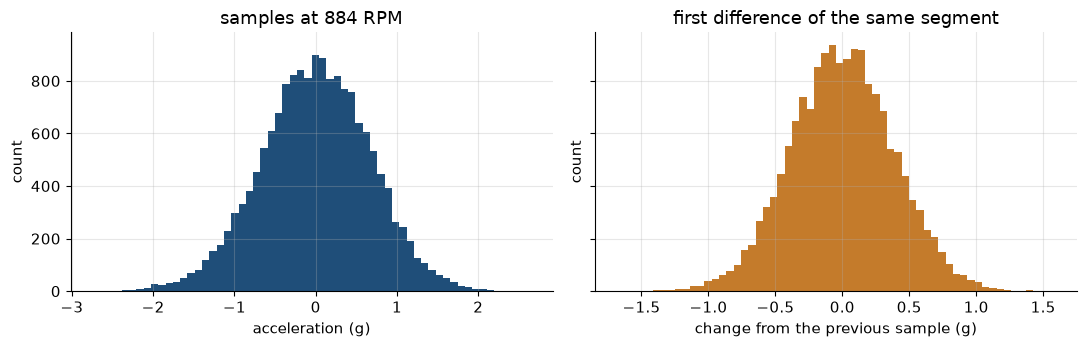

Segments: 27
Years: 0.00 to 3.84
Speed: 705 to 1160 RPM
RMS: 0.203 to 2.113 g (median 0.760)
Median peak 3.039 g
Median lag-1 correlation 0.835
Median std(difference) / std(sample) 0.574
Loudest line within 0.5 of order 35: 59% of segments
Median bins for 50% of the power: 11 of 8192
Median bins for 90% of the power: 1057 of 8192
Median kurtosis 2.9 (Gaussian would be 3)

A row is one channel of acceleration, already cut into fixed blocks, with the shaft speed written beside the block. The speed is one number next to 16384 samples, so it is cheap side information, and the plots say a model should use it.
The loud line moves in hertz when the speed changes, and it usually stays at the same shaft order. In this subset, 59% of segments have their loudest line within half an order of 35. A few others sit near 17, 25, 70, or 105. The first shaft harmonic, near 12–19 Hz, is not the signal.
Half the power sits in about 11 frequency bins. Getting to 90% takes about 1057 bins out of 8192. A han

In [5]:
n50 = np.array([energy_bins(x, 0.50) for x in samples])
n90 = np.array([energy_bins(x, 0.90) for x in samples])
peak_ord = np.array([main_peak(x, speed)[1] for x, speed in zip(samples, rpm)])
rms = np.array([row["rms"] for row in stats])
dstd = np.array([row["dstd"] for row in stats])
lag1 = np.array([row["lag1"] for row in stats])
kurt = np.array([row["kurt"] for row in stats])
n_bins = n_samples // 2
frac_35 = np.mean(np.abs(peak_ord - 35) < 0.5)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].scatter(rpm, rms, c="#1f4e79", s=28)
axes[0].set_xlabel("speed (RPM)")
axes[0].set_ylabel("RMS (g)")
axes[0].set_title("amplitude against speed")

axes[1].scatter(rpm, peak_ord, c="#1f4e79", s=28)
axes[1].set_xlabel("speed (RPM)")
axes[1].set_ylabel("order of the loudest line")
axes[1].set_title("loudest line, in shaft orders")

axes[2].scatter(rpm, n90, c="#1f4e79", s=28)
axes[2].set_xlabel("speed (RPM)")
axes[2].set_ylabel("bins for 90% of power")
axes[2].set_title(f"spectral floor, out of {n_bins} bins")
fig.tight_layout()
plt.show()

example = samples[mid]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
axes[0].hist(example, bins=60, color="#1f4e79")
axes[0].set_title(f"samples at {rpm[mid]:.0f} RPM")
axes[0].set_xlabel("acceleration (g)")
axes[1].hist(np.diff(example), bins=60, color="#c47b2b")
axes[1].set_title("first difference of the same segment")
axes[1].set_xlabel("change from the previous sample (g)")
for ax in axes:
    ax.set_ylabel("count")
fig.tight_layout()
plt.show()

print(f"Segments: {n_seg}")
print(f"Years: {years.min():.2f} to {years.max():.2f}")
print(f"Speed: {rpm.min():.0f} to {rpm.max():.0f} RPM")
print(f"RMS: {rms.min():.3f} to {rms.max():.3f} g (median {np.median(rms):.3f})")
print(f"Median peak {np.median([row['peak'] for row in stats]):.3f} g")
print(f"Median lag-1 correlation {np.median(lag1):.3f}")
print(f"Median std(difference) / std(sample) {np.median(dstd):.3f}")
print(f"Loudest line within 0.5 of order 35: {100 * frac_35:.0f}% of segments")
print(f"Median bins for 50% of the power: {np.median(n50):.0f} of {n_bins}")
print(f"Median bins for 90% of the power: {np.median(n90):.0f} of {n_bins}")
print(f"Median kurtosis {np.median(kurt):.1f} (Gaussian would be 3)")
print()
print(
    "A row is one channel of acceleration, already cut into fixed blocks, "
    "with the shaft speed written beside the block. The speed is one number "
    f"next to {n_samples} samples, so it is cheap side information, and the "
    "plots say a model should use it."
)
print(
    "The loud line moves in hertz when the speed changes, and it usually "
    f"stays at the same shaft order. In this subset, {100 * frac_35:.0f}% of "
    "segments have their loudest line within half an order of 35. A few others "
    "sit near 17, 25, 70, or 105. The first shaft harmonic, near 12–19 Hz, "
    "is not the signal."
)
print(
    f"Half the power sits in about {np.median(n50):.0f} frequency bins. "
    f"Getting to 90% takes about {np.median(n90):.0f} bins out of {n_bins}. "
    "A handful of tones can describe the loud part. They do not describe the rest."
)
print(
    "Predicting a sample from the previous sample only helps modestly. "
    f"The median lag-1 correlation is {np.median(lag1):.2f}, and the first "
    f"difference still has {np.median(dstd):.2f} times the standard deviation "
    "of the raw segment. The tones are hundreds of hertz, so the waveform "
    "moves from one sample to the next. The opening is to predict those "
    "tones from the speed, not to store a delta."
)
if np.median(kurt) > 4:
    print(
        "Kurtosis is above a Gaussian, so the segments have sharper peaks "
        "than a few tones would leave behind."
    )
else:
    print(
        "Kurtosis of the raw segments stays near a Gaussian, so this subset "
        "is not a series of rare spikes. The broad floor in the spectrum "
        "is the part a few tones do not capture."
    )
print(
    "Nothing in the file says how many millig of error a user can accept. "
    "A lossy model has to state that choice. Comparisons later should use "
    f"the numeric samples (float32 is {n_samples * 4:,} bytes, and changes "
    f"this subset by at most {err_f32:.1e} g) rather than the CSV text, "
    "which is several times larger only because the numbers are written in decimal."
)
